In [12]:
import ants
import nibabel as nib
import numpy as np
import pandas as pd

In [5]:
# Calculate Mutual Information using ANTsPy
def mutual_information(img1, img2, bins=32):
    """Calculate mutual information between two images using ANTsPy."""
    if img1 is None or img2 is None:
        return None
    # Convert numpy arrays to ANTs images
    img1_ants = ants.from_numpy(img1.astype(np.float32))
    img2_ants = ants.from_numpy(img2.astype(np.float32))
    # Calculate mutual information directly with ANTsPy
    return ants.image_mutual_information(img1_ants, img2_ants)

In [19]:
T_AV45 = pd.read_csv("/host/verges/tank/data/jack/AV45/BIDS_ADNI_AV45/AV45_shortlist_demographics.csv")
BIDS_AV45 = '/host/verges/tank/data/jack/AV45/BIDS_ADNI_AV45'

mi_values = []

for subj in T_AV45['Subject_short']:
    img1 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_AV45}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-AV45_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)
    
T_AV45['Mutual_Information'] = mi_values



In [20]:
T_AV45

,Image Data ID,Subject,Subject_short,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,Downloaded,Mutual_Information
0,I11418499,404_S_10846,404S10846,AD,M,72,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV22),Original,8/14/2025,DCM,Yes,-0.330904
1,I11340082,389_S_10860,389S10860,AD,M,84,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV21),Original,7/07/2025,DCM,Yes,-0.494338
2,I11283875,389_S_10676,389S10676,AD,M,78,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV21),Original,5/16/2025,DCM,Yes,-0.551477
3,I11325622,334_S_10813,334S10813,AD,M,70,4_sc,MRI,Accelerated Sagittal MPRAGE,Original,6/06/2025,DCM,Yes,-0.260168
4,I11329794,334_S_10727,334S10727,AD,F,66,4_sc,MRI,Accelerated Sagittal MPRAGE,Original,4/30/2025,DCM,Yes,-0.319336
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,I11065360,052_S_10354,052S10354,MCI,M,87,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV21),Original,11/26/2024,DCM,Yes,-0.542180
96,I10927896,052_S_10195,052S10195,MCI,F,88,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV21),Original,8/16/2024,DCM,Yes,-0.484616
97,I10888810,052_S_10159,052S10159,MCI,F,59,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV21),Original,7/18/2024,DCM,Yes,-0.436022
98,I11325614,037_S_10639,037S10639,MCI,M,76,4_sc,MRI,Accelerated Sagittal MPRAGE (MSV21),Original,6/23/2025,DCM,Yes,-0.439907


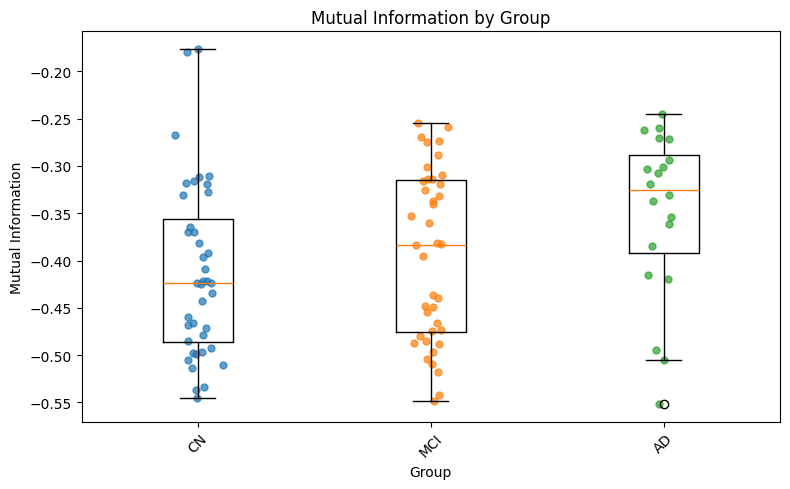

In [35]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = T_AV45[["Group", "Mutual_Information"]].dropna()
# groups = sorted(plot_df["Group"].unique())
groups = ["CN", "MCI", "AD"]

data_by_group = [
    plot_df.loc[plot_df["Group"] == g, "Mutual_Information"].values
    for g in groups
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_group, labels=groups)

# Overlay individual data points with horizontal jitter
rng = np.random.default_rng(42)
for i, y in enumerate(data_by_group, start=1):
    x = rng.normal(loc=i, scale=0.05, size=len(y))
    ax.scatter(x, y, alpha=0.7, s=25)

ax.set_title("Mutual Information by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Mutual Information")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
T_MK6240 = pd.read_csv("/host/verges/tank/data/jack/MK6240/BIDS_test_MK6240_ADNI4/MK6240_shortlist_demographics.csv")
T_MK6240 = T_MK6240[T_MK6240['Subject_short'] != "016S10441"]  # Exclude subject 016S10441
BIDS_MK6240 = '/host/verges/tank/data/jack/MK6240/BIDS_test_MK6240_ADNI4'

mi_values = []

for subj in T_MK6240['Subject_short']:
    img1 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/anat/sub-{subj}_ses-01_space-nativepro_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_MK6240}/derivatives/MICA-PET_v.alpha.0.5/sub-{subj}/ses-01/pet/sub-{subj}_ses-01_space-T1wNativepro_pvc-none_ref-none_trc-MK6240_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

T_MK6240['Mutual_Information'] = mi_values


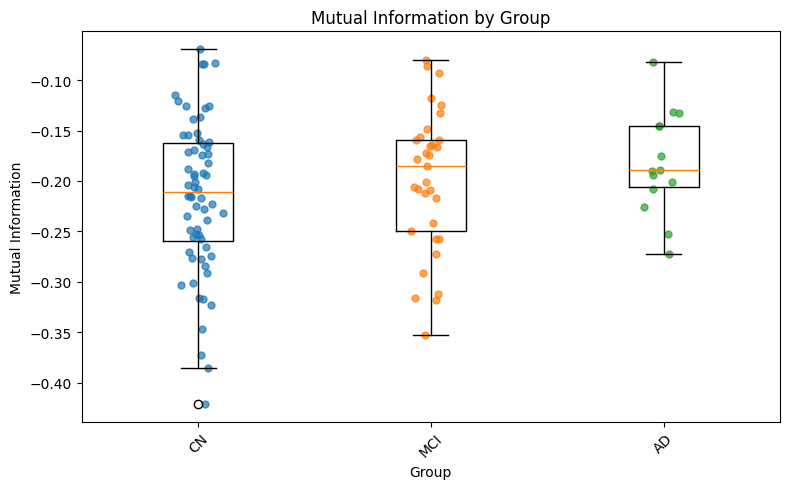

In [36]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = T_MK6240[["Group", "Mutual_Information"]].dropna()
# groups = sorted(plot_df["Group"].unique())
groups = ["CN", "MCI", "AD"]

data_by_group = [
    plot_df.loc[plot_df["Group"] == g, "Mutual_Information"].values
    for g in groups
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_group, labels=groups)

# Overlay individual data points with horizontal jitter
rng = np.random.default_rng(42)
for i, y in enumerate(data_by_group, start=1):
    x = rng.normal(loc=i, scale=0.05, size=len(y))
    ax.scatter(x, y, alpha=0.7, s=25)

ax.set_title("Mutual Information by Group")
ax.set_xlabel("Group")
ax.set_ylabel("Mutual Information")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
T_FDG = pd.read_csv("/host/verges/tank/data/mo/BIDS_20251201_TLE_BTTH1/BIDS_BTTH1_demo.csv")
BIDS_FDG = '/host/verges/tank/data/mo/BIDS_20251201_TLE_BTTH1'

mi_values = []

for subj in T_FDG['ID']:
    subj = subj.removeprefix("sub-")
    
    img1 = nib.load(f'{BIDS_FDG}/rawdata/sub-{subj}/ses-pre/anat/sub-{subj}_ses-pre_T1w.nii.gz').get_fdata()
    img2 = nib.load(f'{BIDS_FDG}/derivatives/MICA-PET_v.alpha.0.3/sub-{subj}/ses-pre/pet/sub-{subj}_ses-pre_space-T1wNative_pvc-none_ref-none_trc-FDG_pet.nii.gz').get_fdata()
    mi = mutual_information(img1, img2)
    mi_values.append(mi)

T_FDG['Mutual_Information'] = mi_values

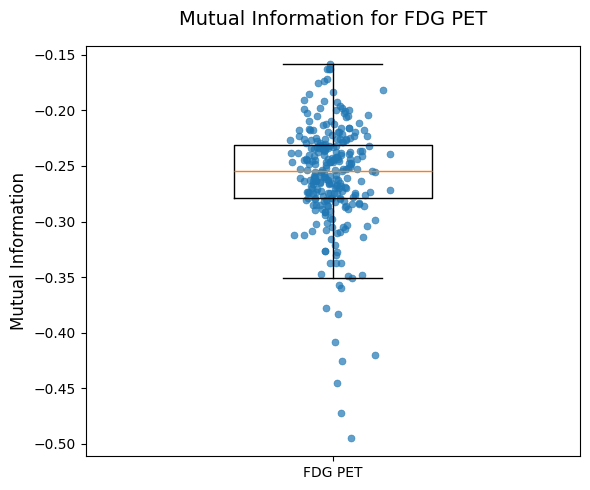

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Clean data and extract the values as a flat 1D array
plot_data = T_FDG["Mutual_Information"].dropna().values

fig, ax = plt.subplots(figsize=(6, 5))

# 2. Plot the boxplot at X-position 1
ax.boxplot(plot_data, positions=[1], widths=0.4, showfliers=False)

# 3. Vectorized Jitter: Generate X-coordinates for ALL points at once
rng = np.random.default_rng(42)
x_jitter = rng.normal(loc=1, scale=0.04, size=len(plot_data))

# 4. Plot all scatter points in a single call (much faster)
ax.scatter(x_jitter, plot_data, alpha=0.7, s=25, linewidths=0.5)

# 5. Styling and Labels
ax.set_title("Mutual Information for FDG PET", fontsize=14, pad=15)
ax.set_ylabel("Mutual Information", fontsize=12)

# Manually set the X-axis tick since there's only one group
ax.set_xticks([1])
ax.set_xticklabels(["FDG PET"]) 

# Clean up axes limits so the jitter looks centered
ax.set_xlim(0.5, 1.5)

plt.tight_layout()
plt.show()